# Crescent / Cambered-Plate Section Design — Calculations (NB 4)

**Scope.** Exact cross-section of the baseline sail: 8 % circular-arc cambered plate, pivot at 50 % chord, 0.95 m × 0.65 m, foam-core sandwich with rounded edges and a faired mast spine. This notebook covers only the **current baseline and its trade studies**. Superseded estimates go in `3_Design_History.ipynb`; long rationale goes in `claude/design-decisions.md` (D6 and a new section-design entry).

**How to read.** Top to bottom, no chat needed. Sections: 1 Constants · 2 Equations (S1–S19) · 3 Section generator and geometry checks · 4 Thin-airfoil checks · 5 Aero engine (2D tool + 3D correction) · 6 Baseline results · 7 Parametric sweep · 8 One-factor studies (edge radius, spine, thrust vs apparent-wind angle, CFD hand-off) · 9 Literature calibration checkpoints · 10 Summary for other subsystems · 11 References · 12 Assumptions and open items.

**Numbering.** Equations here are prefixed **S** (S1…S19) so they do not clash with the E# equations in `2_Calculations.ipynb`. Sources are `[L#]` (literature, Section 11) and `[P#]` (project docs).

**Confidence statement (read first).** The aero numbers come from NeuralFoil, a 2D surrogate of XFOIL-type boundary-layer analysis [L8]. For a thin, sharp-edged, cambered plate at Re 10⁵–2×10⁵ the literature shows strong separation, laminar-bubble and "lift-crisis" behaviour that 2D tools do not capture well [L4][L2]. Use results to **rank section candidates and bracket Cm**, not as absolute coefficients. The notebook reports NeuralFoil's own analysis-confidence value and brackets transition with Ncrit 9 (free) and Ncrit 4 (early transition). Absolute numbers need the bench test or CFD (Section 12).

## 1. Constants and inputs
All baseline values come from `claude/pdr-rough-sizing.md` v5 [P1]. Anything not from [P1] is marked **(assumed)** and listed in Section 12.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
import neuralfoil as nf
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi":110, "axes.grid":True, "grid.alpha":0.3})

# ---- Planform and section baseline [P1 s.1] ----
SPAN   = 0.95            # m
CHORD  = 0.65            # m
AREA   = SPAN*CHORD      # m^2  (0.62)
AR     = SPAN**2/AREA    # -   (1.46)
R_ARC  = 1.04            # m, baseline arc radius
F_C0   = 0.08            # camber ratio f/c (sagitta/chord)
X_PIV  = 0.50            # pivot, fraction of chord from LE

# ---- Structure -> section thickness [P1 s.1] ----
T_CORE = 10.0e-3         # m, PVC foam core
T_PLY  = 0.20e-3         # m per cured 200 g/m^2 E-glass ply        (assumed)
N_PLY  = 2               # plies per face
T_PLATE = T_CORE + 2*N_PLY*T_PLY       # m  (10.8 mm)
T_SPINE = 55.0e-3        # m, local thickness at mast
W_SPINE = 0.100          # m, half-length of spine fairing (+-100 mm)
D_MAST  = 42.0e-3        # m

# ---- Air and loads ----
KN   = 0.514444          # m/s per knot
RHO  = 1.225             # kg/m^3  (15 C, sea level)
NU   = 1.46e-5           # m^2/s   kinematic viscosity (15 C)
E_SPAN = 0.80            # span efficiency for lifting-line correction  (assumed)

# ---- Drive reference loads [P1 s.8] ----
M_OP, M_HOLD, M_STATIC = 19.0, 63.0, 94.0      # N*m  operating @27 kn / hold @50 kn broadside / static
V_OP, V_SURV = 27*KN, 50*KN
q_of = lambda V: 0.5*RHO*V**2

# ---- Reynolds-number cases used in the studies (Eq. S7) ----
RE_CASES = {"light 4 kn":4*KN*CHORD/NU, "mid 8 kn":8*KN*CHORD/NU, "fresh 12 kn":12*KN*CHORD/NU, "strong 27 kn":27*KN*CHORD/NU}
RE_LO, RE_MID, RE_HI = 9e4, 1.8e5, 6e5      # rounded cases used in sweeps (4, 8, 27 kn apparent wind)

# ---- Angle-of-attack grid for 2D polars ----
ALPHA = np.arange(-8.0, 31.0, 1.0)         # deg

print(f"Area {AREA:.3f} m^2, AR {AR:.2f}, plate thickness {T_PLATE*1e3:.1f} mm (t/c {T_PLATE/CHORD:.4f})")
for k,v in RE_CASES.items(): print(f"  Re({k}) = {v:.2e}")
print(f"q(27 kn) = {q_of(V_OP):.0f} Pa,  q(50 kn) = {q_of(V_SURV):.0f} Pa")

Area 0.617 m^2, AR 1.46, plate thickness 10.8 mm (t/c 0.0166)
  Re(light 4 kn) = 9.16e+04
  Re(mid 8 kn) = 1.83e+05
  Re(fresh 12 kn) = 2.75e+05
  Re(strong 27 kn) = 6.18e+05
q(27 kn) = 118 Pa,  q(50 kn) = 405 Pa


## 2. Equations
Chord $c$, camber (sagitta) $f$, $x$ measured from the leading edge in the plate frame, $x_p = X_{PIV}\,c$.

**Geometry**

$$R=\frac{c^{2}/4+f^{2}}{2f}\tag{S1}$$

$$y_c(x)=\sqrt{R^{2}-(x-c/2)^{2}}-(R-f)\tag{S2}$$

$$\theta(x)=\arctan\!\big(dy_c/dx\big)\tag{S3}$$

Half-thickness with elliptical edges of chordwise length $L_e$ (same at both ends; $s=\min(x,\,c-x)$ is the distance to the nearest edge) [form follows the rounded-edge families of [L1]]:

$$y_t(s)=\frac{t}{2}\sqrt{1-\Big(\frac{L_e-s}{L_e}\Big)^{2}}\ \ (s<L_e),\qquad y_t=\frac t2\ \ (s\ge L_e);\qquad r_{tip}=\frac{(t/2)^{2}}{L_e}\tag{S4}$$

Spine fairing (symmetric cos² bump about the pivot, zero slope at its ends):

$$\Delta y_t=\frac{t_s-t}{2}\cos^{2}\!\Big(\frac{\pi (x-x_p)}{2w}\Big),\quad |x-x_p|<w\tag{S5}$$

Surface points (upper = convex side, lower = concave/pressure side):

$$x_{u,l}=x\mp y_t\sin\theta,\qquad y_{u,l}=y_c\pm y_t\cos\theta\tag{S6}$$

**Flow and thin-airfoil checks**

$$Re=\frac{V_{app}\,c}{\nu}\tag{S7}$$

$$\alpha_{L0}=-\frac1\pi\int_0^\pi\frac{dy_c}{dx}(\cos\theta'-1)\,d\theta' \;\approx\;-2\,\frac fc\ \text{(parabolic arc)}\tag{S8}$$

$$C_{m,c/4}=\frac{\pi}{4}(A_2-A_1)\;\approx\;-\pi\,\frac fc,\qquad A_n=\frac2\pi\int_0^\pi\frac{dy_c}{dx}\cos n\theta'\,d\theta'\tag{S9}$$

with $x=\tfrac c2(1-\cos\theta')$ [L10].

**3D (low-aspect-ratio) correction** — lifting-line induced angle, applied on top of the 2D polar [L10][L2]:

$$\alpha_i=\frac{C_L}{\pi e\,AR}\tag{S10}$$

$$C_L^{3D}(\alpha)=C_L^{2D}(\alpha-\alpha_i)\ \ \text{(solved iteratively)}\tag{S11}$$

$$C_D^{3D}=C_D^{2D}(\alpha-\alpha_i)+\frac{(C_L^{3D})^{2}}{\pi e\,AR}\tag{S12}$$

**Moment about the pivot and drive torque.** XFOIL/NeuralFoil report $C_m$ about $x/c=0.25$ (nose-up positive); transferring to the pivot with normal-force coefficient $C_N=C_L\cos\alpha+C_D\sin\alpha$ (the normal force acts at $x_{cp}$ and gives $-C_N(x_{cp}-x_{ref})$ about any reference point, so moving the reference aft by $\Delta x$ adds $+C_N\Delta x$):

$$C_{m,p}=C_{m,c/4}+(X_{PIV}-0.25)\,C_N\tag{S13}$$

$$M_p=q\,S\,c\,C_{m,p}\tag{S14}$$

$$x_{cp}/c = X_{PIV}-C_{m,p}/C_N\tag{S15}$$

Reference moment coefficient implied by the current drive requirement [P1 s.8] (hold torque at 50 kn broadside, magnitudes added):

$$C_{m,hold}^{ref}=\frac{M_{hold}}{q_{50}\,S\,c},\qquad L/D=\frac{C_L^{3D}}{C_D^{3D}}\tag{S16}$$

**Thrust versus apparent-wind angle (Section 8c).** Apparent wind of speed $V_a$ at angle $\beta$ from the bow (β = 90° beam, 180° dead run), sail at angle of attack $\alpha$ to the apparent wind:

$$F_{drive}=qS\,(C_L\sin\beta-C_D\cos\beta),\qquad F_{side}=qS\,(C_L\cos\beta+C_D\sin\beta)\tag{S17}$$

Post-stall coefficients, flat-plate (Viterna–Corrigan) extrapolation from the stall point $(\alpha_s,C_{L,s},C_{D,s})$ to broadside [L11]:

$$C_L=A_1\sin2\alpha+A_2\frac{\cos^{2}\alpha}{\sin\alpha},\quad C_D=B_1\sin^{2}\alpha+B_2\cos\alpha,\quad A_1=\tfrac{C_{D,90}}{2},\ B_1=C_{D,90},$$
$$A_2=\frac{(C_{L,s}-C_{D,90}\sin\alpha_s\cos\alpha_s)\sin\alpha_s}{\cos^{2}\alpha_s},\quad B_2=\frac{C_{D,s}-C_{D,90}\sin^{2}\alpha_s}{\cos\alpha_s}\tag{S18}$$

Heel limit: the sail may be trimmed (or depowered) so that the heeling moment stays below the righting moment at 20° [P1]:

$$F_{side}\le F_{side,max}=\frac{RM_{20}}{l_{heel}}\tag{S19}$$

## 3. Section generator and geometry checks
Implements S1–S6. Returns coordinates normalised by chord, ordered upper TE → LE → lower TE (the NeuralFoil/XFOIL convention). Positive camber is upward, so the **lower** surface is the concave pressure side at positive angle of attack. On the other tack the sail is rotated end-for-end; because the section is fore-aft symmetric (S2, S4, S5 are symmetric about mid-chord), the aerodynamics on that tack are identical.

S1: R = 1.0416 m   (baseline 1.04 m)
Section: 321 points, max camber-line height check (centre) = 52.0 mm
Tip radius (Le=1.5% c): 3.0 mm   (full-round would be 5.4 mm)


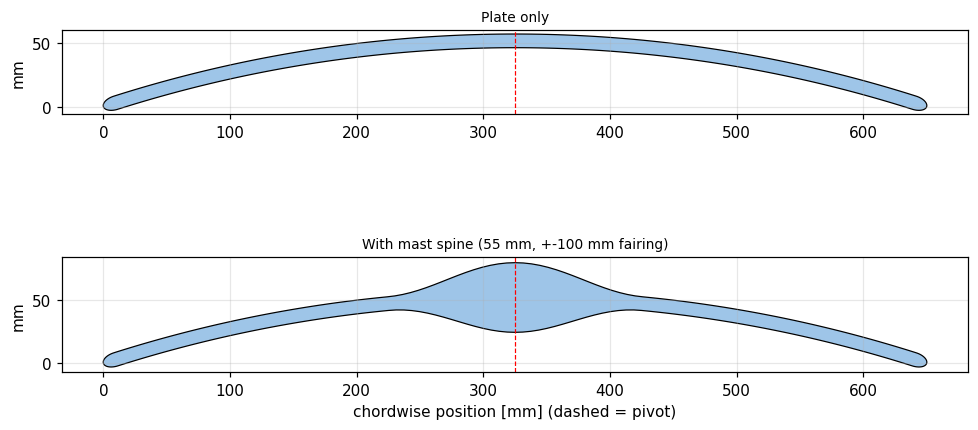

In [2]:
def arc_radius(f, c):                      # Eq. S1
    return (c**2/4 + f**2)/(2*f)

def section(f_c=F_C0, t_c=T_PLATE/CHORD, Le_c=0.015, spine=False, n=161):
    # Plate section with elliptical edges (S4) and optional symmetric spine (S5); coordinates / chord.
    c = 1.0; f = f_c*c; t = t_c*c; Le = Le_c*c
    R = arc_radius(f, c)
    th = np.linspace(0, np.pi, n); x = 0.5*c*(1-np.cos(th))             # cosine spacing
    yc = np.sqrt(R**2-(x-c/2)**2) - (R-f)                                # S2
    ang = np.arctan(-(x-c/2)/np.sqrt(R**2-(x-c/2)**2))                   # S3
    s = np.minimum(x, c-x)
    yt = np.where(s<Le, 0.5*t*np.sqrt(np.clip(1-((Le-s)/Le)**2,0,1)), 0.5*t)   # S4
    if spine:
        ts = T_SPINE/CHORD; w = W_SPINE/CHORD; xp = X_PIV*c
        m = np.abs(x-xp)<w
        yt = yt + np.where(m, 0.5*(ts-t)*np.cos(np.pi*(x-xp)/(2*w))**2, 0.0)  # S5
    xu, yu = x - yt*np.sin(ang), yc + yt*np.cos(ang)                     # S6
    xl, yl = x + yt*np.sin(ang), yc - yt*np.cos(ang)
    X = np.concatenate([xu[::-1], xl[1:]]); Y = np.concatenate([yu[::-1], yl[1:]])
    return np.stack([X, Y], 1)

# ---- Check against baseline [P1 s.1]: sagitta 52 mm, R = 1.04 m ----
f0 = F_C0*CHORD
print(f"S1: R = {arc_radius(f0, CHORD):.4f} m   (baseline 1.04 m)")
sec0 = section()
print(f"Section: {len(sec0)} points, max camber-line height check (centre) = {(F_C0*CHORD*1e3):.1f} mm")
print(f"Tip radius (Le=1.5% c): {(0.5*T_PLATE)**2/(0.015*CHORD)*1e3:.1f} mm   (full-round would be {0.5*T_PLATE*1e3:.1f} mm)")

fig, ax = plt.subplots(2, 1, figsize=(9, 5.2), gridspec_kw={"height_ratios":[1,1]})
for a, sp, ttl in [(ax[0], False, "Plate only"), (ax[1], True, "With mast spine (55 mm, +-100 mm fairing)")]:
    s_ = section(spine=sp)*CHORD*1e3
    a.fill(s_[:,0], s_[:,1], color="#9ec5e8", ec="k", lw=0.8)
    a.axvline(X_PIV*CHORD*1e3, color="r", ls="--", lw=0.8); a.set_aspect("equal"); a.set_title(ttl, fontsize=9)
    a.set_ylabel("mm")
ax[1].set_xlabel("chordwise position [mm] (dashed = pivot)")
plt.tight_layout(); plt.show()

## 4. Thin-airfoil checks (S8, S9)
Numerical integration of the actual camber line (S2), compared with the closed-form parabolic-arc results. This validates the geometry and gives the zero-lift angle and quarter-chord moment the 2D tool should approach at low angle of attack.

In [3]:
def thin_airfoil(f_c, n=4001):
    c=1.0; f=f_c; R=arc_radius(f,c)
    thp = np.linspace(0, np.pi, n); x = 0.5*(1-np.cos(thp))
    dydx = -(x-0.5)/np.sqrt(R**2-(x-0.5)**2)
    aL0 = -(1/np.pi)*np.trapezoid(dydx*(np.cos(thp)-1), thp)               # S8
    A1 = (2/np.pi)*np.trapezoid(dydx*np.cos(thp), thp)
    A2 = (2/np.pi)*np.trapezoid(dydx*np.cos(2*thp), thp)
    cm = (np.pi/4)*(A2-A1)                                                  # S9
    return np.degrees(aL0), cm

for fc in [0.05, 0.06, 0.08, 0.10]:
    aL0, cm = thin_airfoil(fc)
    print(f"f/c = {fc:.2f}:  alpha_L0 = {aL0:6.2f} deg (approx {-np.degrees(2*fc):6.2f}),  Cm_c/4 = {cm:6.3f} (approx {-np.pi*fc:6.3f})")
aL0_base, cm_base = thin_airfoil(F_C0)

f/c = 0.05:  alpha_L0 =  -5.76 deg (approx  -5.73),  Cm_c/4 = -0.158 (approx -0.157)
f/c = 0.06:  alpha_L0 =  -6.93 deg (approx  -6.88),  Cm_c/4 = -0.190 (approx -0.188)
f/c = 0.08:  alpha_L0 =  -9.29 deg (approx  -9.17),  Cm_c/4 = -0.255 (approx -0.251)
f/c = 0.10:  alpha_L0 = -11.69 deg (approx -11.46),  Cm_c/4 = -0.321 (approx -0.314)


## 5. Aero engine: 2D polar (NeuralFoil) + 3D correction
`polar2d` calls NeuralFoil [L8] (model size `xlarge`) over the angle grid. `to3d` applies S10–S13. Both return NeuralFoil's `analysis_confidence`; values below ~0.5 are flagged because the surrogate is outside the regime it was trained to be reliable in.

Transition bracket: Ncrit 9 (free transition, clean low-turbulence flow) and Ncrit 4 (earlier transition, rougher/turbulent ocean air). The real sail should sit between them.

In [4]:
CONF_FLAG = 0.5

def polar2d(coords, Re, ncrit=9.0, alpha=ALPHA):
    r = nf.get_aero_from_coordinates(coordinates=coords, alpha=alpha, Re=Re, n_crit=ncrit, model_size="xlarge")
    return {k: np.asarray(r[k]) for k in ("CL","CD","CM","analysis_confidence")} | {"alpha": alpha}

def to3d(p2, ar=AR, e=E_SPAN, x_p=X_PIV, alpha3=None):
    # S10-S13: damped fixed-point solve for CL3D at each geometric alpha.
    a2, CL2, CD2, CM2, conf = p2["alpha"], p2["CL"], p2["CD"], p2["CM"], p2["analysis_confidence"]
    alpha3 = a2 if alpha3 is None else alpha3
    k = 1/(np.pi*e*ar); CL = np.interp(alpha3, a2, CL2)*0.4
    for _ in range(200):
        ae = alpha3 - np.degrees(k*CL)                                      # S10
        new = np.interp(ae, a2, CL2); CL = 0.6*CL + 0.4*new                # S11
    ae = alpha3 - np.degrees(k*CL)
    CD = np.interp(ae, a2, CD2) + k*CL**2                                   # S12
    CMq = np.interp(ae, a2, CM2); cf = np.interp(ae, a2, conf)
    ar_ = np.radians(alpha3); CN = CL*np.cos(ar_) + CD*np.sin(ar_)
    CMp = CMq + (x_p-0.25)*CN                                               # S13
    xcp = np.where(np.abs(CN)>0.05, x_p - CMp/np.where(np.abs(CN)>0.05, CN, 1), np.nan)   # S15
    return {"alpha": alpha3, "alpha_eff": ae, "CL": CL, "CD": CD, "CMq": CMq, "CMp": CMp, "xcp": xcp, "LD": CL/CD, "conf": cf}

# quick sanity: baseline polar at Re 1.8e5
p = polar2d(section(), RE_MID); r3 = to3d(p)
i = np.argmin(np.abs(ALPHA-4))
print(f"2D @ 4 deg: CL {p['CL'][i]:.3f}, CD {p['CD'][i]:.4f}, CMq {p['CM'][i]:.3f}, conf {p['analysis_confidence'][i]:.2f}")
print(f"3D @ 4 deg: CL {r3['CL'][i]:.3f}, CD {r3['CD'][i]:.4f}, CMp {r3['CMp'][i]:.3f}")

2D @ 4 deg: CL 1.237, CD 0.0218, CMq -0.208, conf 0.90
3D @ 4 deg: CL 0.387, CD 0.0847, CMp -0.072


## 6. Baseline results (8 % arc, 10.8 mm plate, 1.5 % c edge ellipse)
2D and 3D polars at the three Reynolds numbers, bracketing transition. Shaded markers show where analysis confidence < 0.5.

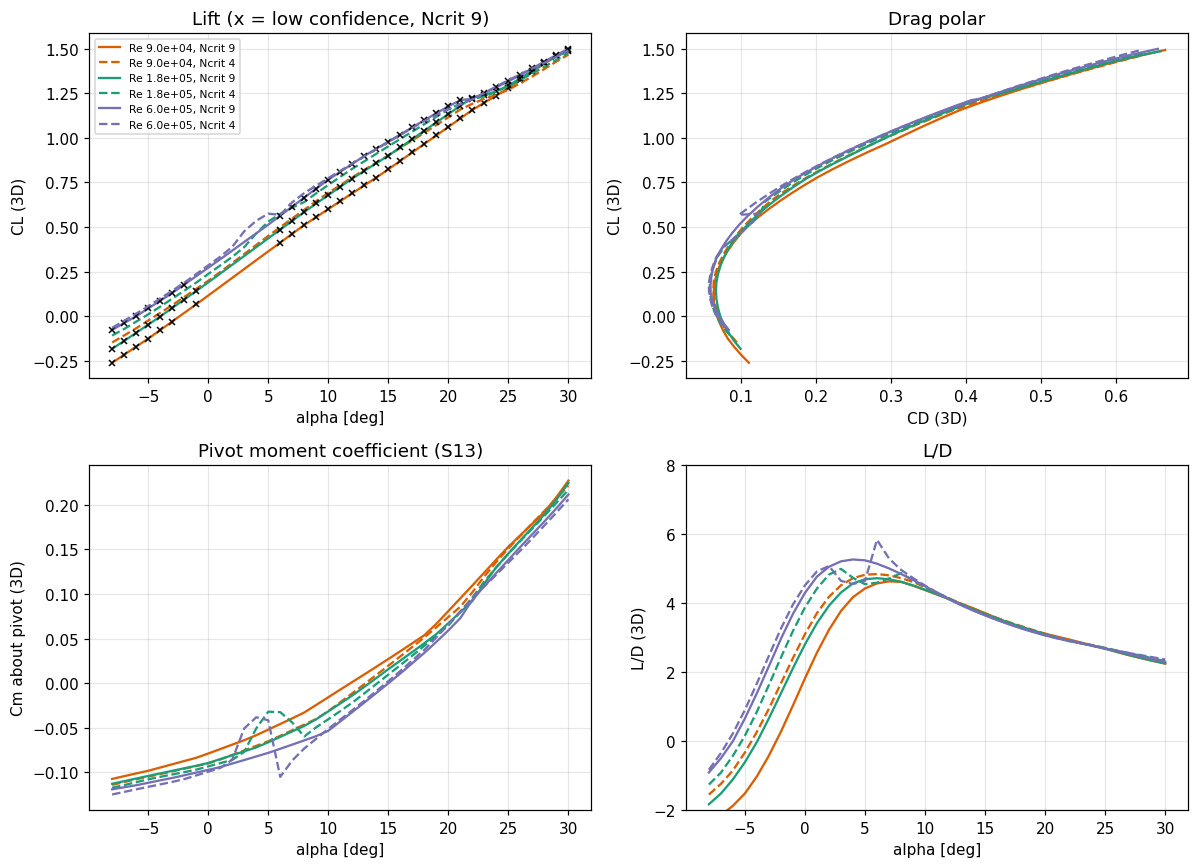

,Re,Ncrit,CLmax3D,a_CLmax,LDmax3D,a_LDmax,CL_10deg,Cmp_at_CLmax,absCmp_max,conf_min,conf_0_10
0,9.0e+04,9.0,1.279,25.0,4.627,7.0,0.601,0.153,0.153,0.007,0.012
1,9.0e+04,4.0,1.270,25.0,4.840,6.0,0.691,0.151,0.151,0.023,0.367
2,1.8e+05,9.0,1.294,25.0,4.719,6.0,0.679,0.145,0.145,0.004,0.015
3,1.8e+05,4.0,1.291,25.0,4.989,3.0,0.736,0.145,0.145,0.017,0.344
4,6.0e+05,9.0,1.317,25.0,5.261,4.0,0.765,0.138,0.138,0.001,0.015
5,6.0e+05,4.0,1.323,25.0,5.831,6.0,0.775,0.135,0.135,0.008,0.346


NOTE: CL is still rising at the 25 deg search limit in every case, i.e. NeuralFoil + lifting-line show no stall inside 0-25 deg.
      CLmax3D above is therefore CL(25 deg), a lower bound, not a stall value. Zhu [L2] and Bot [L4] both report stall/jump behaviour that this engine does not capture.


In [5]:
base = section()
res = {}
for Re in (RE_LO, RE_MID, RE_HI):
    for nc in (9.0, 4.0):
        p2 = polar2d(base, Re, nc); res[(Re,nc)] = (p2, to3d(p2))

fig, axs = plt.subplots(2, 2, figsize=(11, 8))
cols = {RE_LO:"#d95f02", RE_MID:"#1b9e77", RE_HI:"#7570b3"}
for (Re,nc),(p2,r3) in res.items():
    ls = "-" if nc==9 else "--"; lab = f"Re {Re:.1e}, Ncrit {nc:.0f}"
    axs[0,0].plot(r3["alpha"], r3["CL"], ls, c=cols[Re], label=lab)
    axs[0,1].plot(r3["CD"], r3["CL"], ls, c=cols[Re])
    axs[1,0].plot(r3["alpha"], r3["CMp"], ls, c=cols[Re])
    axs[1,1].plot(r3["alpha"], r3["LD"], ls, c=cols[Re])
    bad = p2["analysis_confidence"] < CONF_FLAG
    if nc==9:
        axs[0,0].plot(r3["alpha"][bad], r3["CL"][bad], "x", c="k", ms=4)
axs[0,0].set(xlabel="alpha [deg]", ylabel="CL (3D)", title="Lift (x = low confidence, Ncrit 9)"); axs[0,0].legend(fontsize=7)
axs[0,1].set(xlabel="CD (3D)", ylabel="CL (3D)", title="Drag polar")
axs[1,0].set(xlabel="alpha [deg]", ylabel="Cm about pivot (3D)", title="Pivot moment coefficient (S13)")
axs[1,1].set(xlabel="alpha [deg]", ylabel="L/D (3D)", title="L/D"); axs[1,1].set_ylim(-2, 8)
plt.tight_layout(); plt.show()

rows=[]
for (Re,nc),(p2,r3) in res.items():
    m = (r3["alpha"]>=0)&(r3["alpha"]<=25); j = np.argmax(np.where(m, r3["LD"], -9))
    k = np.argmax(np.where(m, r3["CL"], -9)); a10 = np.argmin(np.abs(r3["alpha"]-10))
    rows.append(dict(Re=f"{Re:.1e}", Ncrit=nc, CLmax3D=r3["CL"][k], a_CLmax=r3["alpha"][k], LDmax3D=r3["LD"][j], a_LDmax=r3["alpha"][j],
                     CL_10deg=r3["CL"][a10], Cmp_at_CLmax=r3["CMp"][k], absCmp_max=np.max(np.abs(r3["CMp"][m])),
                     conf_min=float(p2["analysis_confidence"][m].min()), conf_0_10=float(p2["analysis_confidence"][(ALPHA>=0)&(ALPHA<=10)].min())))
base_tab = pd.DataFrame(rows).round(3); display(base_tab)
if (base_tab.a_CLmax >= 25).all():
    print("NOTE: CL is still rising at the 25 deg search limit in every case, i.e. NeuralFoil + lifting-line show no stall inside 0-25 deg.")
    print("      CLmax3D above is therefore CL(25 deg), a lower bound, not a stall value. Zhu [L2] and Bot [L4] both report stall/jump behaviour that this engine does not capture.")

In [6]:
# ---- Drive-torque check against the project requirements (S14, S16) ----
S_c = AREA*CHORD
cm_ref_hold = M_HOLD/(q_of(V_SURV)*S_c)                                   # S16
cm_ref_op   = M_OP/(q_of(V_OP)*S_c)
r_hi = res[(RE_HI, 9.0)][1]; m = (r_hi["alpha"]>=0)&(r_hi["alpha"]<=25)
print(f"Reference Cm at hold (63 N*m, 50 kn):  {cm_ref_hold:.3f}   |   at operating (19 N*m, 27 kn): {cm_ref_op:.3f}")
_pk = np.max(np.abs(r_hi['CMp'][m]))
print(f"Section max |Cm_p| over 0-25 deg, Re 6e5, 3D: {_pk:.3f}  ->  {_pk*q_of(V_OP)*S_c:.1f} N*m at 27 kn, {_pk*q_of(V_SURV)*S_c:.1f} N*m at 50 kn")
print("The project operating/hold values (19 / 63 N*m) are well above this lift-regime value because they include stalled and broadside loading; the 2D-based engine cannot check them (Section 12).")
print("Broadside (alpha = 90 deg) is outside the 2D polar range: that case uses the project value CF ~ 1.35 [P1], not this notebook.")
print(f"Moment of pure camber (Cm_c/4 {cm_base:.3f}) at 27 kn: {abs(cm_base)*q_of(V_OP)*S_c:.1f} N*m (about c/4; the pivot adds the lift term)")

Reference Cm at hold (63 N*m, 50 kn):  0.387   |   at operating (19 N*m, 27 kn): 0.401
Section max |Cm_p| over 0-25 deg, Re 6e5, 3D: 0.138  ->  6.6 N*m at 27 kn, 22.5 N*m at 50 kn
The project operating/hold values (19 / 63 N*m) are well above this lift-regime value because they include stalled and broadside loading; the 2D-based engine cannot check them (Section 12).
Broadside (alpha = 90 deg) is outside the 2D polar range: that case uses the project value CF ~ 1.35 [P1], not this notebook.
Moment of pure camber (Cm_c/4 -0.255) at 27 kn: 12.1 N*m (about c/4; the pivot adds the lift term)


## 7. Parametric sweep (ranking)
Variables: camber $f/c$, plate thickness $t$ (core 8–13 mm), edge ellipse length $L_e$ (sets tip radius, S4). Spine is held on/off in Section 8 because a 55 mm bump on a 10 mm plate is far outside typical thin-section training data.

**Metrics** (all 3D-corrected, mean of Ncrit 9 and 4 where noted):
- $P_{light}$: $C_L$ at 10° and Re $9\times10^{4}$ (light-air drive).
- $P_{reach}$: $(L/D)_{max}$ at Re $1.8\times10^{5}$.
- $T_{hold}$: peak $|C_{m,p}|$ over 0–25° at Re $6\times10^{5}$ (lower is better). This covers the **lift regime only**; the 63 N·m hold in [P1] is set by broadside/post-stall loading that the 2D tool cannot produce, so $T_{hold}$ is a proxy for the camber and lift-arm contribution.
- Min analysis confidence over 0–20° (reliability flag).

**Score** (relative to the baseline candidate, so baseline = 1.00): $J = w_1 P_{light}/P_{light,0} + w_2 P_{reach}/P_{reach,0} - w_3 T_{hold}/T_{hold,0}$. Weights are inputs, not results.

In [7]:
W = dict(light=0.40, reach=0.30, torque=0.30)          # weights (inputs; edit to taste)

def eval_candidate(f_c, t_m, Le_c, spine=False):
    sec = section(f_c=f_c, t_c=t_m/CHORD, Le_c=Le_c, spine=spine)
    out = {}
    lo  = [to3d(polar2d(sec, RE_LO, nc)) for nc in (9.0, 4.0)]
    mid = [to3d(polar2d(sec, RE_MID, nc)) for nc in (9.0, 4.0)]
    hi  = to3d(polar2d(sec, RE_HI, 9.0))
    ia = np.argmin(np.abs(ALPHA-10)); msk = (ALPHA>=0)&(ALPHA<=25)
    out["P_light"] = np.mean([r["CL"][ia] for r in lo])
    out["P_reach"] = np.mean([np.max(np.where(msk, r["LD"], -9)) for r in mid])
    out["T_hold"]  = np.max(np.abs(hi["CMp"][msk]))
    out["conf_min"] = min(r["conf"][(ALPHA>=0)&(ALPHA<=20)].min() for r in lo+mid+[hi])
    return out

grid_f  = [0.05, 0.06, 0.07, 0.08, 0.09, 0.10]
grid_t  = [8.0e-3, T_PLATE, 13.0e-3]
grid_Le = [0.0083, 0.015, 0.030]
import time; t0=time.time()
rows=[]
for f_c in grid_f:
    for t_m in grid_t:
        for Le_c in grid_Le:
            o = eval_candidate(f_c, t_m, Le_c); o.update(f_c=f_c, t_mm=t_m*1e3, Le_pct=Le_c*100, r_tip_mm=(0.5*t_m)**2/(Le_c*CHORD)*1e3)
            rows.append(o)
sweep = pd.DataFrame(rows); print(f"{len(sweep)} candidates in {time.time()-t0:.0f} s")
b = sweep[(sweep.f_c==F_C0)&(np.isclose(sweep.t_mm, T_PLATE*1e3))&(np.isclose(sweep.Le_pct,1.5))].iloc[0]
sweep["J"] = (W["light"]*sweep.P_light/b.P_light + W["reach"]*sweep.P_reach/b.P_reach - W["torque"]*sweep.T_hold/b.T_hold)
sweep["J"] = sweep.J - (W["light"]+W["reach"]-W["torque"]) + 1.0      # so baseline J = 1.00
print("Baseline candidate:", b[["P_light","P_reach","T_hold","conf_min"]].round(3).to_dict())
display(sweep.sort_values("J", ascending=False).head(10).round(3))

54 candidates in 1 s
Baseline candidate: {'P_light': 0.646, 'P_reach': 4.854, 'T_hold': 0.138, 'conf_min': 0.134}


,P_light,P_reach,T_hold,conf_min,f_c,t_mm,Le_pct,r_tip_mm,J
46,0.639,4.498,0.095,0.098,0.10,8.0,1.50,1.641,1.068
50,0.649,4.410,0.097,0.127,0.10,10.8,3.00,1.495,1.064
48,0.650,4.355,0.098,0.145,0.10,10.8,0.83,5.405,1.058
49,0.650,4.355,0.098,0.143,0.10,10.8,1.50,2.991,1.058
47,0.641,4.456,0.099,0.077,0.10,8.0,3.00,0.821,1.057
52,0.651,4.344,0.100,0.192,0.10,13.0,1.50,4.333,1.054
53,0.651,4.332,0.100,0.169,0.10,13.0,3.00,2.167,1.054
51,0.650,4.299,0.100,0.161,0.10,13.0,0.83,7.831,1.050
39,0.669,4.685,0.117,0.136,0.09,10.8,0.83,5.405,1.049
45,0.646,4.394,0.103,0.101,0.10,8.0,0.83,2.966,1.049


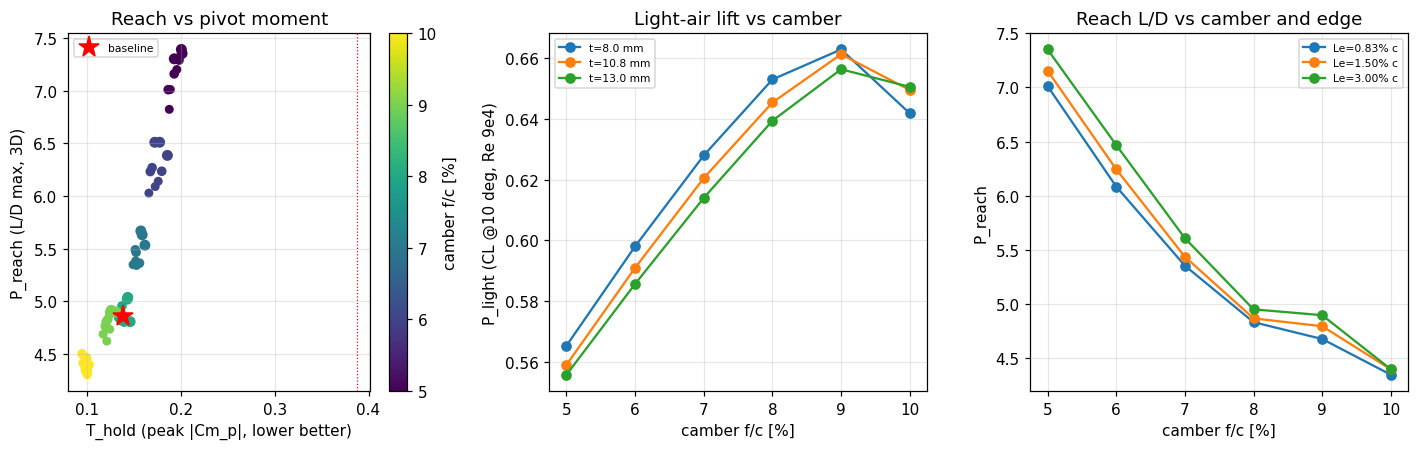

Mean effect per factor (candidates grouped):


,P_light,P_reach,T_hold,conf_min,J
f_c,,,,,
0.05,0.560,7.173,0.194,0.191,0.969
0.06,0.592,6.267,0.174,0.150,0.976
0.07,0.621,5.468,0.155,0.140,0.987
0.08,0.646,4.885,0.139,0.134,1.000
0.09,0.660,4.791,0.123,0.131,1.038
0.10,0.647,4.382,0.099,0.135,1.057


,P_light,P_reach,T_hold,conf_min,J
t_mm,,,,,
8.0,0.625,5.505,0.150,0.099,1.001
10.8,0.621,5.509,0.147,0.150,1.007
13.0,0.617,5.469,0.145,0.192,1.005


,P_light,P_reach,T_hold,conf_min,J
Le_pct,,,,,
0.83,0.628,5.386,0.145,0.140,1.007
1.50,0.621,5.484,0.146,0.153,1.007
3.00,0.613,5.613,0.151,0.147,0.999


Relative spread across each factor (percent of mean):
                   P_light  P_reach  T_hold
camber 5-10 %         16.1     50.8    64.5
thickness 8-13 mm      1.3      0.7     3.4
edge Le 0.8-3 %c       2.4      4.1     4.1

READING: camber 5->10 %: P_light rises (0.56->0.65), P_reach falls (7.2->4.4), lift-regime pivot moment T_hold falls (0.19->0.10).
Camber is the only factor that moves the metrics well beyond tool noise; thickness and edge radius move them by a few percent at most, so choose those for manufacturing and structure unless bench data say otherwise.
Caution on J: P_reach is flattered by the tool at low camber (it misses separation drag, Section 9) and T_hold covers only the lift regime (0-25 deg), not the broadside/post-stall case that sets the 63 N*m hold. The J winner sits on a grid edge. Treat J as a trend indicator, not an optimum. Min analysis confidence is low (<0.3 over 0-25 deg).


In [8]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
sc = axs[0].scatter(sweep.T_hold, sweep.P_reach, c=sweep.f_c*100, cmap="viridis", s=18+10*(sweep.Le_pct/1.5)); plt.colorbar(sc, ax=axs[0], label="camber f/c [%]")
axs[0].set(xlabel="T_hold (peak |Cm_p|, lower better)", ylabel="P_reach (L/D max, 3D)", title="Reach vs pivot moment")
axs[0].plot(b.T_hold, b.P_reach, "r*", ms=14, label="baseline"); axs[0].axvline(cm_ref_hold, c="r", ls=":", lw=0.8); axs[0].legend(fontsize=7)
for tm, g in sweep.groupby("t_mm"): axs[1].plot(g.groupby("f_c").P_light.mean().index*100, g.groupby("f_c").P_light.mean(), "o-", label=f"t={tm:.1f} mm")
axs[1].set(xlabel="camber f/c [%]", ylabel="P_light (CL @10 deg, Re 9e4)", title="Light-air lift vs camber"); axs[1].legend(fontsize=7)
for Le, g in sweep.groupby("Le_pct"): axs[2].plot(g.groupby("f_c").P_reach.mean().index*100, g.groupby("f_c").P_reach.mean(), "o-", label=f"Le={Le:.2f}% c")
axs[2].set(xlabel="camber f/c [%]", ylabel="P_reach", title="Reach L/D vs camber and edge"); axs[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Mean effect per factor (candidates grouped):")
for col in ("f_c","t_mm","Le_pct"): display(sweep.groupby(col)[["P_light","P_reach","T_hold","conf_min","J"]].mean().round(3))
gf = sweep.groupby("f_c")[["P_light","P_reach","T_hold"]].mean(); gt = sweep.groupby("t_mm")[["P_light","P_reach","T_hold"]].mean(); gl = sweep.groupby("Le_pct")[["P_light","P_reach","T_hold"]].mean()
spread = lambda g: ((g.max()-g.min())/g.mean()*100).round(1)
print("Relative spread across each factor (percent of mean):")
print(pd.DataFrame({"camber 5-10 %":spread(gf), "thickness 8-13 mm":spread(gt), "edge Le 0.8-3 %c":spread(gl)}).T)
print()
dirn = lambda g,c: "rises" if g[c].iloc[-1]>g[c].iloc[0] else "falls"
print(f"READING: camber 5->10 %: P_light {dirn(gf,'P_light')} ({gf.P_light.iloc[0]:.2f}->{gf.P_light.iloc[-1]:.2f}), P_reach {dirn(gf,'P_reach')} ({gf.P_reach.iloc[0]:.1f}->{gf.P_reach.iloc[-1]:.1f}), lift-regime pivot moment T_hold {dirn(gf,'T_hold')} ({gf.T_hold.iloc[0]:.2f}->{gf.T_hold.iloc[-1]:.2f}).")
print("Camber is the only factor that moves the metrics well beyond tool noise; thickness and edge radius move them by a few percent at most, so choose those for manufacturing and structure unless bench data say otherwise.")
print("Caution on J: P_reach is flattered by the tool at low camber (it misses separation drag, Section 9) and T_hold covers only the lift regime (0-25 deg), not the broadside/post-stall case that sets the 63 N*m hold. The J winner sits on a grid edge. Treat J as a trend indicator, not an optimum. Min analysis confidence is low (<0.3 over 0-25 deg).")

## 8. One-factor studies at the baseline
**8a. Edge geometry** (tip radius, S4) across the three Reynolds numbers and both transition settings. **8b. Spine on/off** (S5): a symmetric 55 mm fairing is the only way the structure sees the mast; this quantifies what NeuralFoil thinks it costs. Treat 8b as a flag, not a number — the bump is far outside the surrogate's training range (low confidence expected).

In [9]:
rows=[]
for Le_c in (0.0083, 0.015, 0.03):
    for Re in (RE_LO, RE_MID, RE_HI):
        for nc in (9.0, 4.0):
            r3 = to3d(polar2d(section(Le_c=Le_c), Re, nc)); m=(r3["alpha"]>=0)&(r3["alpha"]<=25)
            rows.append(dict(Le_pct=Le_c*100, r_tip_mm=round((0.5*T_PLATE)**2/(Le_c*CHORD)*1e3,1), Re=f"{Re:.0e}", Ncrit=nc,
                             CLmax=r3["CL"][m].max(), LDmax=r3["LD"][m].max(), absCmp=np.abs(r3["CMp"][m]).max(), conf=r3["conf"][m].min()))
edge_tab = pd.DataFrame(rows).round(3); display(edge_tab)

,Le_pct,r_tip_mm,Re,Ncrit,CLmax,LDmax,absCmp,conf
0,0.83,5.4,9e+04,9.0,1.291,4.557,0.149,0.365
1,0.83,5.4,9e+04,4.0,1.279,4.761,0.149,0.730
2,0.83,5.4,2e+05,9.0,1.306,4.675,0.142,0.281
3,0.83,5.4,2e+05,4.0,1.302,5.029,0.142,0.742
4,0.83,5.4,6e+05,9.0,1.329,5.224,0.135,0.132
5,0.83,5.4,6e+05,4.0,1.335,5.826,0.132,0.420
6,1.50,3.0,9e+04,9.0,1.279,4.627,0.153,0.383
7,1.50,3.0,9e+04,4.0,1.270,4.840,0.151,0.744
8,1.50,3.0,2e+05,9.0,1.294,4.719,0.145,0.302
9,1.50,3.0,2e+05,4.0,1.291,4.989,0.145,0.745


In [10]:
rows=[]
for sp in (False, True):
    for Re in (RE_LO, RE_MID, RE_HI):
        for nc in (9.0, 4.0):
            r3 = to3d(polar2d(section(spine=sp), Re, nc)); m=(r3["alpha"]>=0)&(r3["alpha"]<=25)
            rows.append(dict(spine=sp, Re=f"{Re:.0e}", Ncrit=nc, CLmax=r3["CL"][m].max(), LDmax=r3["LD"][m].max(), absCmp=np.abs(r3["CMp"][m]).max(), conf=r3["conf"][m].min()))
spine_tab = pd.DataFrame(rows).round(3); display(spine_tab)
print("WARNING: with the spine, NeuralFoil analysis confidence is ~0 (conf column): the surrogate is far outside its training range. Rows below are NOT interpretable aerodynamics; spine drag/lift needs CFD or bench data.")
dd = spine_tab.pivot_table(index=["Re","Ncrit"], columns="spine", values=["CLmax","LDmax"]).round(3)
print("Spine effect (True - False):"); display((dd.xs(True, axis=1, level=1)-dd.xs(False, axis=1, level=1)).round(3))

,spine,Re,Ncrit,CLmax,LDmax,absCmp,conf
0,False,9e+04,9.0,1.279,4.627,0.153,0.383
1,False,9e+04,4.0,1.270,4.840,0.151,0.744
2,False,2e+05,9.0,1.294,4.719,0.145,0.302
3,False,2e+05,4.0,1.291,4.989,0.145,0.745
4,False,6e+05,9.0,1.317,5.261,0.138,0.134
5,False,6e+05,4.0,1.323,5.831,0.135,0.427
6,True,9e+04,9.0,1.261,4.050,0.150,0.000
7,True,9e+04,4.0,1.261,4.673,0.148,0.003
8,True,2e+05,9.0,1.290,4.700,0.144,0.000
9,True,2e+05,4.0,1.310,5.240,0.140,0.002


Spine effect (True - False):


CLmax  LDmax
Re    Ncrit              
2e+05 4.0    0.019  0.251
      9.0   -0.004 -0.019
6e+05 4.0    0.043 -1.315
      9.0    0.038  0.063
9e+04 4.0   -0.009 -0.167
      9.0   -0.018 -0.577

## 8c. Thrust versus apparent-wind angle (camber 6 / 8 / 10 % vs NACA 0015)
Question: where is the sail power-limited (so camber helps) and where is it heel-limited or downwind (so camber doesn't matter)?

**Method.** For each section, apparent-wind speed $V_a$ and angle $\beta$, choose the trim angle $\alpha$ that maximises drive force (S17) subject to the heel limit (S19). Coefficients: 3D-corrected NeuralFoil polars (mean of Ncrit 9 and 4, Reynolds number set by $V_a$) up to a stall angle, then the flat-plate extrapolation (S18) to broadside.

**Limits.** Apparent wind is held fixed: no hull resistance, so this is *drive force*, not boat speed. The stall angle of the plate is an **input** (12°, from [P1]); the tool does not predict it (Section 6). The NACA 0015 stall angle comes from its own 2D polar plus the induced angle. All of it inherits the tool's optimism on drag (Section 9), so a plate run with drag × 2 is shown alongside.

In [11]:
# ---- Inputs for 8c ----
RM20       = 19.3                     # N*m righting moment at 20 deg, 7 kg bulb @ 0.28 m  [P1 summary]
L_HEEL     = 0.91                     # m, CE to CLR heeling arm [P1 s.2]
F_SIDE_MAX = RM20/L_HEEL              # S19, N
CD90       = 1.35                     # broadside force coefficient [P1 inputs]
STALL_PLATE = 12.0                    # deg, geometric stall of the plate (assumed from [P1]; sensitivity below)
ALPHA_EXT  = np.arange(-8.0, 46.0, 1.0)
VG = np.arange(4.0, 32.0, 2.0)        # apparent wind speeds, kn
BETA = np.arange(30.0, 181.0, 5.0)    # apparent wind angle from bow, deg
A_FINE = np.arange(-8.0, 90.01, 0.5)
print(f"Heel-limited side force F_side,max = {F_SIDE_MAX:.1f} N  (RM20 {RM20} N*m / arm {L_HEEL} m)")

def naca4_sym(t_c, n=161):
    th = np.linspace(0, np.pi, n); x = 0.5*(1-np.cos(th))
    yt = 5*t_c*(0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1036*x**4)
    return np.stack([np.r_[x[::-1], x[1:]], np.r_[yt[::-1], -yt[1:]]], 1)

SECTIONS = {"plate 6 %": section(f_c=0.06), "plate 8 %": section(f_c=0.08), "plate 10 %": section(f_c=0.10), "NACA 0015": naca4_sym(0.15)}
_cache = {}
def base_polar(name, V_kn):
    key = (name, V_kn)
    if key not in _cache:
        Re = V_kn*KN*CHORD/NU; co = SECTIONS[name]
        p9 = polar2d(co, Re, 9.0, alpha=ALPHA_EXT); p4 = polar2d(co, Re, 4.0, alpha=ALPHA_EXT)
        p = {k: 0.5*(p9[k]+p4[k]) for k in ("CL","CD","CM","analysis_confidence")}; p["alpha"] = ALPHA_EXT
        _cache[key] = (p, to3d(p))
    return _cache[key]

def coeffs(name, V_kn, stall_geo=None, drag_mult=1.0):
    p, r3 = base_polar(name, V_kn)
    if stall_geo is None:                              # tool-derived: 2D CL peak (0-25 deg) mapped to geometric angle
        m = (ALPHA_EXT>=0)&(ALPHA_EXT<=25); ae_s = ALPHA_EXT[np.argmax(np.where(m, p["CL"], -9))]
        ok = np.where(r3["alpha_eff"] >= ae_s)[0]; stall_geo = r3["alpha"][ok[0]] if len(ok) else ALPHA_EXT[-1]
    CLs = np.interp(stall_geo, r3["alpha"], r3["CL"]); CDs = np.interp(stall_geo, r3["alpha"], r3["CD"])*drag_mult
    a = A_FINE; ar = np.radians(a); sa, ca = np.sin(np.radians(stall_geo)), np.cos(np.radians(stall_geo))
    A2 = (CLs - CD90*sa*ca)*sa/ca**2; B2 = (CDs - CD90*sa**2)/ca
    with np.errstate(all="ignore"):
        CLv = 0.5*CD90*np.sin(2*ar) + A2*np.cos(ar)**2/np.sin(ar); CDv = CD90*np.sin(ar)**2 + B2*np.cos(ar)
    pre = a <= stall_geo
    CL = np.where(pre, np.interp(a, r3["alpha"], r3["CL"]), CLv); CD = np.where(pre, np.interp(a, r3["alpha"], r3["CD"])*drag_mult, CDv)
    return dict(a=a, CL=CL, CD=CD, stall=stall_geo)

def best_drive(c, V_kn, beta_deg):
    q = q_of(V_kn*KN); b = np.radians(beta_deg)
    F_dr = q*AREA*(c["CL"]*np.sin(b) - c["CD"]*np.cos(b)); F_sd = np.abs(q*AREA*(c["CL"]*np.cos(b) + c["CD"]*np.sin(b)))   # S17
    ok = c["CL"] >= 0
    iu = np.argmax(np.where(ok, F_dr, -1e9)); ic = np.argmax(np.where(ok & (F_sd <= F_SIDE_MAX), F_dr, -1e9))
    return F_dr[ic], F_dr[iu], F_sd[iu] > F_SIDE_MAX, c["a"][ic]

VARIANTS = {"plate 6 %":("plate 6 %", STALL_PLATE, 1.0), "plate 8 %":("plate 8 %", STALL_PLATE, 1.0), "plate 10 %":("plate 10 %", STALL_PLATE, 1.0),
            "plate 8 %, drag x2":("plate 8 %", STALL_PLATE, 2.0), "plate 8 %, stall 18 deg":("plate 8 %", 18.0, 1.0), "NACA 0015":("NACA 0015", None, 1.0)}
res8 = {}
for lab, (nm, st, dm) in VARIANTS.items():
    for V in VG:
        c = coeffs(nm, V, st, dm)
        res8[(lab, V)] = [best_drive(c, V, b) for b in BETA]       # per beta: (drive_constrained, drive_unconstrained, heel_limited, alpha_trim)
print("NACA 0015 tool-derived geometric stall angle at 10 kn:", round(coeffs("NACA 0015", 10.0)["stall"],1), "deg")

Heel-limited side force F_side,max = 21.2 N  (RM20 19.3 N*m / arm 0.91 m)


NACA 0015 tool-derived geometric stall angle at 10 kn: 33.0 deg


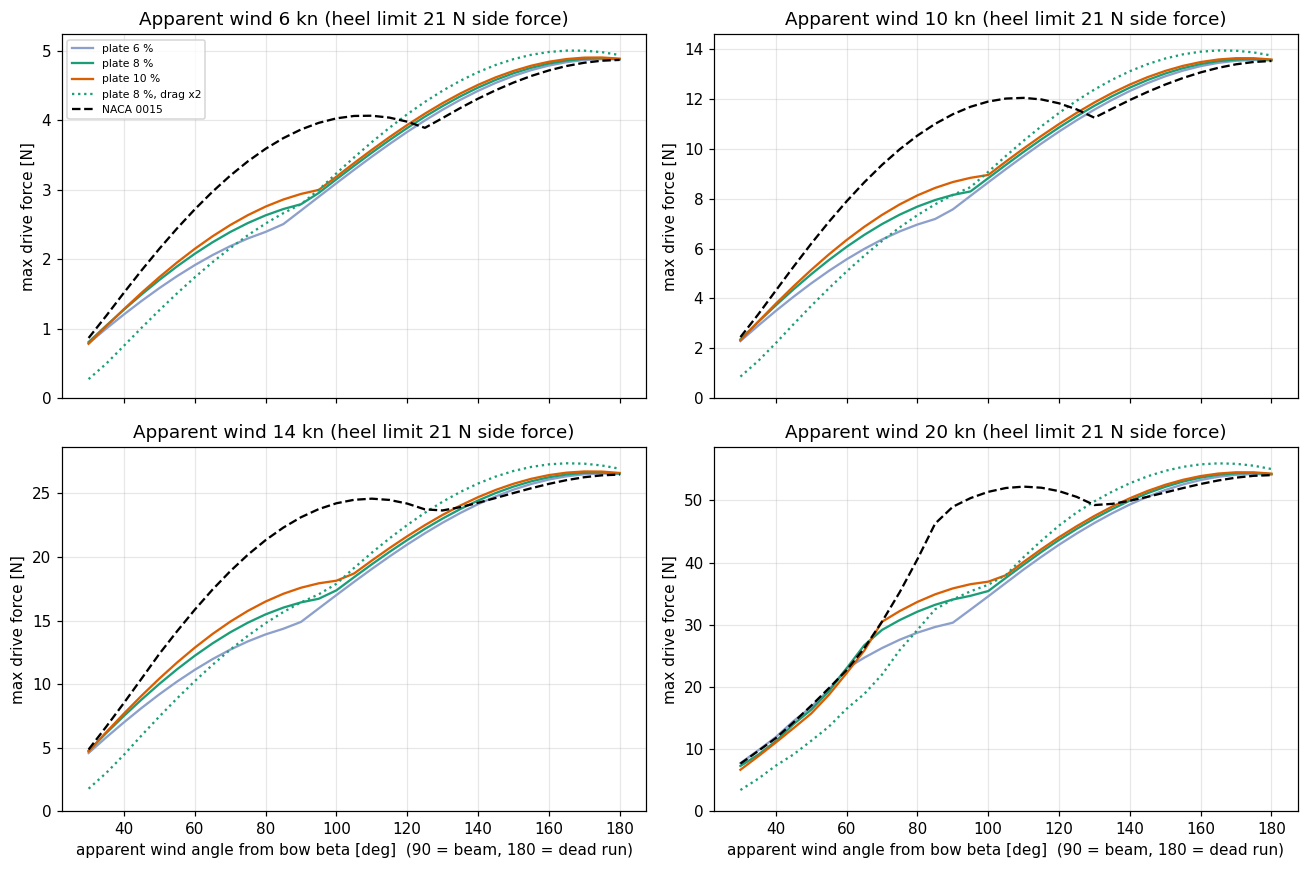

,Va kn,beta,plate 6 %,plate 8 %,plate 10 %,"plate 8 %, drag x2","plate 8 %, stall 18 deg",NACA 0015,plate8/foil
0,6.0,60,1.9,2.1,2.1,1.7,2.7,2.7,0.76
1,6.0,90,2.7,2.8,2.9,2.8,3.7,3.9,0.72
2,6.0,120,3.8,3.9,3.9,4.1,4.1,4.0,0.98
3,6.0,150,4.6,4.7,4.7,4.9,4.8,4.5,1.03
4,6.0,180,4.9,4.9,4.9,4.9,4.9,4.9,1.00
5,10.0,60,5.6,6.1,6.3,5.1,7.7,7.9,0.77
6,10.0,90,7.6,8.1,8.7,8.1,10.8,11.4,0.72
7,10.0,120,10.7,10.8,11.0,11.4,11.5,11.8,0.92
8,10.0,150,12.9,13.0,13.1,13.6,13.3,12.6,1.04
9,10.0,180,13.5,13.6,13.6,13.7,13.6,13.5,1.00


Smallest apparent-wind speed [kn] at which the best-drive trim exceeds the heel limit (power-limited below this):


,beta,plate 6 %,plate 8 %,plate 10 %,NACA 0015
0,60,22.0,20.0,20.0,16.0
1,90,20.0,>30,30.0,22.0
2,120,20.0,22.0,22.0,>30
3,150,28.0,30.0,30.0,>30
4,180,>30,>30,>30,>30


In [12]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
sty = {"plate 6 %":("#8da0cb","-"), "plate 8 %":("#1b9e77","-"), "plate 10 %":("#d95f02","-"), "plate 8 %, drag x2":("#1b9e77",":"), "NACA 0015":("k","--")}
for ax, V in zip(axs.flat, (6.0, 10.0, 14.0, 20.0)):
    for lab,(col,ls) in sty.items(): ax.plot(BETA, [r[0] for r in res8[(lab, V)]], ls, c=col, label=lab)
    ax.set(title=f"Apparent wind {V:.0f} kn (heel limit {F_SIDE_MAX:.0f} N side force)", ylabel="max drive force [N]"); ax.set_ylim(bottom=0)
for ax in axs[1]: ax.set_xlabel("apparent wind angle from bow beta [deg]  (90 = beam, 180 = dead run)")
axs[0,0].legend(fontsize=7); plt.tight_layout(); plt.show()

rows=[]
for V in (6.0, 10.0, 14.0, 20.0):
    for bt in (60, 90, 120, 150, 180):
        i = int(np.argmin(np.abs(BETA-bt))); r = {lab: res8[(lab, V)][i][0] for lab in VARIANTS}
        rows.append({"Va kn":V, "beta":bt, **{k: round(v,1) for k,v in r.items()}, "plate8/foil": round(r["plate 8 %"]/r["NACA 0015"], 2) if r["NACA 0015"]>0 else np.nan})
thrust_tab = pd.DataFrame(rows); display(thrust_tab)

# apparent-wind speed at which each variant becomes heel-limited (smallest V with unconstrained optimum over the limit)
rows=[]
for bt in (60, 90, 120, 150, 180):
    i = int(np.argmin(np.abs(BETA-bt))); r = {"beta":bt}
    for lab in ("plate 6 %","plate 8 %","plate 10 %","NACA 0015"):
        lim = [V for V in VG if res8[(lab, V)][i][2]]; r[lab] = lim[0] if lim else ">30"
    rows.append(r)
print("Smallest apparent-wind speed [kn] at which the best-drive trim exceeds the heel limit (power-limited below this):")
display(pd.DataFrame(rows))

**Reading Section 8c.**
- **Downwind (β ≥ 120°) the section barely matters:** all plate cambers and the NACA 0015 are within a few percent, and at β = 150–180° the plate is equal or slightly ahead. This confirms the downwind argument.
- **Camber (6 → 10 %) matters only on a reach or closer (β ≲ 90°)**, and then by about 5–15 % in 10–20 kn apparent wind (about 5 % at 6 kn, where force is small).
- **Plate versus foil on the reach rests on one assumption.** With the plate stalling at 12° the foil gives ~25–30 % more drive at β = 60–90°. The NACA 0015's tool-derived geometric stall is 33° (2D stall plus the AR 1.46 induced angle), so the two are not on the same footing. With the plate at 18° they are at parity. Resolving this needs the measured plate stall angle (bench test or CFD).
- **Heel limit.** The limit here uses lateral force only (S17, S19), so it binds just on close reaches (β ≈ 60°, from 16–22 kn apparent wind). [P1] treats the whole force as heeling and gets ~12.8 kn full-power wind. The two are not the same measure. This one is less conservative and should be checked with Luis.
- Drag × 2 on the plate changes little except at β = 60° (about −15 to −25 %).

## 8d. CFD hand-off: section files and run matrix
Writes the exact section coordinates used above to `data/cfd_sections/` (metres, chord 0.65 m, leading edge at x = 0, pivot at x = 0.325 m) plus a run matrix, so the ANSYS runs and this notebook share one geometry source. Files are closed loops (first point = last point), ordered upper trailing edge → leading edge → lower trailing edge, `x,y,z` with z = 0, as a comma-separated `.csv` and a space-separated `.txt` (for CAD "curve from file" importers).

**Run conventions for the 2D study.**
- Keep geometry and mesh fixed; change the angle of attack by rotating the inflow direction. For angle $\alpha$ the free-stream direction is $(\cos\alpha,\ \sin\alpha)$, drag direction $(\cos\alpha,\ \sin\alpha)$, lift direction $(-\sin\alpha,\ \cos\alpha)$.
- Moment reference point: the pivot, $(0.325,\ 0)$ m, nose-up positive. Convert with $C_m=M/(\tfrac12\rho V^{2}\,c^{2})$ for unit depth.
- First cell height for $y^+\approx1$ comes from the flat-plate estimate $C_f\approx0.074\,Re^{-0.2}$ (an estimate; confirm $y^+$ in the solution).

In [13]:
import os
OUT = "../data/cfd_sections"; os.makedirs(OUT, exist_ok=True)
CFD_CAMBERS = [0.06, 0.07, 0.08, 0.09, 0.10]
CFD_ALPHAS  = [0, 2, 4, 6, 8, 10, 12, 15, 18, 22, 26, 30]            # deg
CFD_RE      = {"4 kn": 4*KN*CHORD/NU, "8 kn": 8*KN*CHORD/NU, "27 kn": 27*KN*CHORD/NU}

def write_section(fname, co):
    xyz = np.c_[co*CHORD, np.zeros(len(co))]
    assert np.allclose(xyz[0], xyz[-1]), "section loop is not closed"
    np.savetxt(f"{OUT}/{fname}.csv", xyz, delimiter=",", header="x_m,y_m,z_m", comments="", fmt="%.6f")
    np.savetxt(f"{OUT}/{fname}.txt", xyz, delimiter=" ", fmt="%.6f")

for fc in CFD_CAMBERS: write_section(f"section_f{fc*100:04.1f}pct", section(f_c=fc, n=201))
write_section("section_f08.0pct_spine", section(f_c=0.08, spine=True, n=201))

def y1_for_yplus1(Re, V):                      # first-cell height [m] for y+ ~ 1, flat-plate Cf estimate
    cf = 0.074*Re**-0.2; u_tau = V*np.sqrt(cf/2); return NU/u_tau

rows = []
for fc in CFD_CAMBERS:
    for lab, Re in CFD_RE.items():
        V = Re*NU/CHORD
        for a in CFD_ALPHAS:
            ar = np.radians(a)
            rows.append(dict(file=f"section_f{fc*100:04.1f}pct", camber_pct=fc*100, wind=lab, Re=round(Re), V_mps=round(V,3), alpha_deg=a,
                             flow_x=round(np.cos(ar),5), flow_y=round(np.sin(ar),5), lift_x=round(-np.sin(ar),5), lift_y=round(np.cos(ar),5),
                             pivot_x_m=X_PIV*CHORD, y1_m=y1_for_yplus1(Re, V),
                             priority=1 if (abs(fc-0.08)<1e-9 and lab in ("8 kn","27 kn")) else 2))
run_matrix = pd.DataFrame(rows); run_matrix.to_csv(f"{OUT}/run_matrix.csv", index=False)
print(f"Wrote {len(CFD_CAMBERS)+1} section files (.csv + .txt) and run_matrix.csv ({len(run_matrix)} cases) to {OUT}/")
print("Priority 1 (8 % camber, Re 1.8e5 and 6e5, all angles):", int((run_matrix.priority==1).sum()), "cases;  priority 2 (other cambers and Re):", int((run_matrix.priority==2).sum()))
display(pd.DataFrame({"Re": [f"{v:.2e}" for v in CFD_RE.values()], "V [m/s]": [round(v*NU/CHORD,2) for v in CFD_RE.values()],
                      "first cell y+~1 [mm]": [round(y1_for_yplus1(v, v*NU/CHORD)*1e3,3) for v in CFD_RE.values()]}, index=CFD_RE.keys()))
display(run_matrix.head(6))

Wrote 6 section files (.csv + .txt) and run_matrix.csv (180 cases) to data/cfd_sections/
Priority 1 (8 % camber, Re 1.8e5 and 6e5, all angles): 24 cases;  priority 2 (other cambers and Re): 156


,Re,V [m/s],first cell y+~1 [mm]
4 kn,9.16e+04,2.06,0.116
8 kn,1.83e+05,4.12,0.062
27 kn,6.18e+05,13.89,0.021


,file,camber_pct,wind,Re,V_mps,alpha_deg,flow_x,flow_y,lift_x,lift_y,pivot_x_m,y1_m,priority
0,section_f06.0pct,6.0,4 kn,91613,2.058,0,1.00000,0.00000,-0.00000,1.00000,0.325,0.000116,2
1,section_f06.0pct,6.0,4 kn,91613,2.058,2,0.99939,0.03490,-0.03490,0.99939,0.325,0.000116,2
2,section_f06.0pct,6.0,4 kn,91613,2.058,4,0.99756,0.06976,-0.06976,0.99756,0.325,0.000116,2
3,section_f06.0pct,6.0,4 kn,91613,2.058,6,0.99452,0.10453,-0.10453,0.99452,0.325,0.000116,2
4,section_f06.0pct,6.0,4 kn,91613,2.058,8,0.99027,0.13917,-0.13917,0.99027,0.325,0.000116,2
5,section_f06.0pct,6.0,4 kn,91613,2.058,10,0.98481,0.17365,-0.17365,0.98481,0.325,0.000116,2


## 9. Literature calibration checkpoints
Purpose: see how far the 2D+3D engine is from independent measurements. These are **sparse and not like-for-like** (different camber, aspect ratio, edge shape, Re), so they bound the tool's error rather than calibrate it. Reference values are my reading of the cited papers and must be re-checked against the originals before they go into a report.

| Checkpoint | Source | Reported | Notes |
|---|---|---|---|
| 22.3 % circular arc, sharp edge, Re 2.38×10⁵: $C_{L,max}$ | [L4] | ≈ 2.2 | Test aspect ratio to be confirmed from the paper |
| Same: $(L/D)_{max}$ | [L4] | ≈ 14 | Drag minimum an order of magnitude above classical sections |
| 6 % cambered plate, $C_{L,max}$ at Re 2×10⁴ → 10⁶ | [L5] | 1.15 → 1.32 | Wing/plate AR to be confirmed |
| Low-Re ($\lesssim 2\times10^{5}$) cambered plates beat flat plates; TE geometry insensitive | [L6] | qualitative | |

In [14]:
def thin_arc_section(f_c, t_c=0.004, Le_c=0.002):
    return section(f_c=f_c, t_c=t_c, Le_c=Le_c)     # thin, nearly-sharp plate (t/c 0.4 %)

rows=[]
for label, f_c, Re in [("Bot 22.3 %, Re 2.38e5", 0.223, 2.38e5), ("Bot 22.3 %, Re 6.8e4", 0.223, 6.82e4),
                       ("Winslow 6 %, Re 2e4", 0.06, 2e4), ("Winslow 6 %, Re 1e5", 0.06, 1e5), ("Winslow 6 %, Re 1e6", 0.06, 1e6)]:
    for nc in (9.0, 4.0):
        p2 = polar2d(thin_arc_section(f_c), Re, nc)
        rows.append(dict(case=label, Ncrit=nc, CLmax_2D=p2["CL"].max(), LDmax_2D=np.max(p2["CL"]/p2["CD"]), conf_min=float(p2["analysis_confidence"][(ALPHA>=0)&(ALPHA<=20)].min())))
lit_tab = pd.DataFrame(rows).round(3); display(lit_tab)
print("Read-across: Bot CLmax ~2.2 and L/D ~14; Winslow 6 % CLmax 1.15 (Re 2e4) -> 1.32 (Re 1e6). 2D numbers are for infinite span, so expect CLmax_2D above a finite-AR plate.")
bt = lit_tab[lit_tab.case.str.startswith("Bot 22.3 %, Re 2.38")]
print(f"Bot Re 2.38e5: 2D CLmax {bt.CLmax_2D.min():.2f}-{bt.CLmax_2D.max():.2f} vs ~2.2 reported (agrees); 2D L/D max {bt.LDmax_2D.min():.0f}-{bt.LDmax_2D.max():.0f} vs ~14 reported -> tool over-predicts L/D by ~{bt.LDmax_2D.mean()/14:.1f}x.")
print("Analysis confidence is ~0 for these thin, strongly cambered cases, so agreement on CLmax is not evidence of accuracy. Treat all L/D from this engine as optimistic by roughly this factor; relative comparisons are less affected.")

,case,Ncrit,CLmax_2D,LDmax_2D,conf_min
0,"Bot 22.3 %, Re 2.38e5",9.0,2.233,26.596,0.000
1,"Bot 22.3 %, Re 2.38e5",4.0,2.255,29.644,0.001
2,"Bot 22.3 %, Re 6.8e4",9.0,2.222,10.210,0.000
3,"Bot 22.3 %, Re 6.8e4",4.0,2.262,14.558,0.000
4,"Winslow 6 %, Re 2e4",9.0,1.693,21.870,0.552
5,"Winslow 6 %, Re 2e4",4.0,1.681,21.674,0.437
6,"Winslow 6 %, Re 1e5",9.0,1.682,43.018,0.055
7,"Winslow 6 %, Re 1e5",4.0,1.685,54.729,0.080
8,"Winslow 6 %, Re 1e6",9.0,1.686,130.494,0.012
9,"Winslow 6 %, Re 1e6",4.0,1.667,113.583,0.019


Read-across: Bot CLmax ~2.2 and L/D ~14; Winslow 6 % CLmax 1.15 (Re 2e4) -> 1.32 (Re 1e6). 2D numbers are for infinite span, so expect CLmax_2D above a finite-AR plate.
Bot Re 2.38e5: 2D CLmax 2.23-2.25 vs ~2.2 reported (agrees); 2D L/D max 27-30 vs ~14 reported -> tool over-predicts L/D by ~2.0x.
Analysis confidence is ~0 for these thin, strongly cambered cases, so agreement on CLmax is not evidence of accuracy. Treat all L/D from this engine as optimistic by roughly this factor; relative comparisons are less affected.


## 10. Summary for other subsystems
Values are NeuralFoil-based and **ranking-grade**. Ranges span Ncrit 4–9 and Re 9×10⁴–6×10⁵. Nothing here replaces the bench test.

In [15]:
rows=[]
for (Re,nc),(p2,r3) in res.items():
    m=(r3["alpha"]>=0)&(r3["alpha"]<=25); k=np.argmax(np.where(m, r3["CL"], -9))
    rows.append((r3["CL"][k], r3["alpha"][k], r3["xcp"][np.argmin(np.abs(r3["alpha"]-15))], np.abs(r3["CMp"][m]).max(), np.max(r3["LD"][m])))
rows = np.array(rows)
sumtab = pd.DataFrame({
  "Quantity":["CL_max (3D, AR 1.46)","alpha at CL_max [deg]","CP at alpha = 15 deg [x/c]","Peak |Cm_p| over 0-25 deg","(L/D)max (3D)",
              "Lift-regime peak pivot torque at 27 kn [N*m]","Reference operating torque [N*m]","Lift-regime peak pivot torque at 50 kn (NOT broadside) [N*m]","Reference hold torque [N*m]"],
  "Min":[rows[:,0].min(), rows[:,1].min(), rows[:,2].min(), rows[:,3].min(), rows[:,4].min(), rows[:,3].min()*q_of(V_OP)*S_c, M_OP, rows[:,3].min()*q_of(V_SURV)*S_c, M_HOLD],
  "Max":[rows[:,0].max(), rows[:,1].max(), rows[:,2].max(), rows[:,3].max(), rows[:,4].max(), rows[:,3].max()*q_of(V_OP)*S_c, M_OP, rows[:,3].max()*q_of(V_SURV)*S_c, M_HOLD]}).round(2)
display(sumtab)
print("Centre of pressure vs angle (x/c from LE; pivot = 0.50). Compare with the CP ~ 0.30 c assumed in [P1] s.5:")
cp_rows=[]
for (Re,nc),(p2,r3) in res.items():
    cp_rows.append({"Re":f"{Re:.0e}","Ncrit":nc, **{f"a={a:d}":round(float(r3["xcp"][np.argmin(np.abs(r3["alpha"]-a))]),2) for a in (4,8,12,16,20)}})
display(pd.DataFrame(cp_rows))
print("CP flag: this engine puts CP near 0.45-0.6 c in the lift regime (about at the pivot), not ~0.30 c as in [P1] s.5, which changes the CE-vs-mast helm numbers; verify on the bench.")
print("Status: baseline 8 % arc retained. This engine does not support changing camber, thickness or edge shape on its own (see Section 7 reading).")
print("Project docs to update on acceptance: design-decisions D6 (section), pdr-rough-sizing s.1 (section row) and s.8 (Cm / CP assumptions).")

,Quantity,Min,Max
0,"CL_max (3D, AR 1.46)",1.27,1.32
1,alpha at CL_max [deg],25.00,25.00
2,CP at alpha = 15 deg [x/c],0.47,0.50
3,Peak |Cm_p| over 0-25 deg,0.14,0.15
4,(L/D)max (3D),4.63,5.83
5,Lift-regime peak pivot torque at 27 kn [N*m],6.41,7.26
6,Reference operating torque [N*m],19.00,19.00
7,Lift-regime peak pivot torque at 50 kn (NOT br...,21.99,24.89
8,Reference hold torque [N*m],63.00,63.00


Centre of pressure vs angle (x/c from LE; pivot = 0.50). Compare with the CP ~ 0.30 c assumed in [P1] s.5:


,Re,Ncrit,a=4,a=8,a=12,a=16,a=20
0,9e+04,9.0,0.68,0.56,0.50,0.46,0.43
1,9e+04,4.0,0.67,0.58,0.51,0.47,0.44
2,2e+05,9.0,0.68,0.58,0.52,0.47,0.44
3,2e+05,4.0,0.61,0.59,0.53,0.48,0.45
4,6e+05,9.0,0.67,0.59,0.54,0.49,0.45
5,6e+05,4.0,0.57,0.60,0.53,0.49,0.45


CP flag: this engine puts CP near 0.45-0.6 c in the lift regime (about at the pivot), not ~0.30 c as in [P1] s.5, which changes the CE-vs-mast helm numbers; verify on the bench.
Status: baseline 8 % arc retained. This engine does not support changing camber, thickness or edge shape on its own (see Section 7 reading).
Project docs to update on acceptance: design-decisions D6 (section), pdr-rough-sizing s.1 (section row) and s.8 (Cm / CP assumptions).


## 11. References
- **[L1]** Yao (2025), *Chalmers Technical Report TR-2025-1* — crescent / cambered-plate wingsail section parameterisations (circular arcs, mirrored NACA, Bézier, hybrid with bluntness index).
- **[L2]** Zhu et al. (2023), *Ocean Engineering* 285:115349 — uRANS (k-ω SST) study of crescent wingsails; 2D vs 3D differences, unsteady loads, double CL peaks.
- **[L3]** van Reen et al. (2025), *Ocean Engineering* 342:122829 — NeuralFoil + Bayesian optimisation of crescent sections (larger tip radii, lower $t_{max}$ help thrust).
- **[L4]** Bot (2019), *AIAA Journal* — sharp-edged 22.3 % circular-arc plate at Re 6.8×10⁴–3.7×10⁵: lift jump, double stall, vibration, high drag minimum.
- **[L5]** Winslow et al., *AIAA Journal of Aircraft* (DOI 10.2514/1.C034415) — cambered flat plates, camber and Re effects.
- **[L6]** Pelletier & Mueller (2000) — low-Reynolds-number thin cambered plates (Re 6×10⁴–2×10⁵).
- **[L7]** Hoerner, *Fluid-Dynamic Drag* — bluff-body drag coefficients (downwind regime).
- **[L8]** Sharpe, *NeuralFoil* (v0.3.3) and associated paper — physics-informed ML surrogate for XFOIL-type analysis. Confidence value is the tool's own estimate.
- **[L9]** Drela (1989), *XFOIL*, in *Low Reynolds Number Aerodynamics*, Springer LNEng 54 — boundary-layer and Ncrit background.
- **[L10]** Anderson, *Fundamentals of Aerodynamics* — thin-airfoil theory, lifting-line induced angle.
- **[L11]** Viterna & Corrigan (1982), NASA Lewis wind-turbine conference — flat-plate post-stall extrapolation of lift and drag.
- **[P1]** `claude/pdr-rough-sizing.md` v5 (2026-09-26) — baseline geometry, loads, drive requirements.
- **[P2]** `claude/design-decisions.md` — D6 (plate) and related decisions.

*Bibliographic details for [L1]–[L9] were taken from my literature notes; verify page/volume data before citing externally.*

## 12. Assumptions and open items
**Assumptions (this notebook)**
1. Cured E-glass ply 0.20 mm (200 g/m²) → plate 10.8 mm. Replace with the real layup.
2. Span efficiency $e = 0.80$ in S10–S12. At AR 1.46 lifting-line theory is crude; vortex lift (AR < ~1.6) is not modelled and tends to raise real $C_L$ at 15–30°.
3. The 2D $C_m$ at the effective angle is used as the 3D $C_{m,c/4}$ (no separate 3D moment correction).
4. Sweep post-stall points (α up to 30°) come straight from NeuralFoil and are low confidence. Peak values are searched only over 0–25°.
5. Spine is modelled as a symmetric cos² thickening; the real spine/plate bond line and fairing are not.
6. Section 8c: apparent wind fixed (no hull resistance); heel limit = RM at 20° over the 0.91 m arm; plate geometric stall 12° (assumed, [P1]); CD at broadside 1.35 [P1]; mean of Ncrit 9 and 4; trim chosen to maximise drive within the limit.
7. Section is evaluated at the design tack angle; the other tack is identical by fore-aft symmetry. Gusts/unsteady loads (the crescent's known weakness [L2]) are not modelled.

**Open items**
- Bench test (or small CFD) of the baseline plate at Re ~1×10⁵–3×10⁵: CL(α), Cm_pivot(α), stall angle. Use it to rescale the 2D polars (hybrid method of [L2]) before trusting absolute torque.
- Broadside and post-stall hold torque (α 40–90°) is not covered by the 2D tool; keep the project value [P1] until measured.
- Extend 8c with hull resistance to turn drive force into boat speed (needs hull drag data).
- Confirm test AR and exact values for the Section 9 checkpoints in [L4][L5].
- Decide weights W (Section 7) with the team; drive is currently weighted at 0.30.